# Mammarenavirus GPC residue determinants of LASV serum neutralization

**Goal:** use natural sequence variation among Mammarenavirus-derived GPC peptides to nominate amino-acid identities associated with stronger LASV neutralization.

This is a **hypothesis-generating residue analysis**. It does not prove that a residue is mechanistically required for neutralization. The key comparison is between:

- **positive neutralization-associated peptides:** `FDR_screen < 0.05` and `delta_median_neut > 0`
- **all other Mammarenavirus GPC peptides that were tested**

All peptides are mapped onto the LASV Josiah GPC coordinate system. Residue tests are only performed where there is sufficient peptide coverage and amino-acid variation.


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

# ---------- paths ----------
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
REF_FASTA = Path('./ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta')

OUTDIR = Path('./output_figures')
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---------- plotting ----------
SURVIVOR_COLOR = '#D55E00'

plt.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

# ---------- analysis controls ----------
MIN_TOTAL_COVERAGE = 10
MIN_AA_COUNT = 5

# Optional focus after whole-GPC analysis.
# Set to e.g. (350, 420) once you want a GP2 zoom.
FOCUS_REGION = None


## 1. Load data

This notebook assumes the long PhIP-Seq file contains peptide sequence, taxonomy, protein annotation, individual, and reactivity, and that metadata contains neutralization measurements.

If your filenames differ, edit only the paths above.


In [4]:
df = pd.read_csv(LONG_FILE)
meta = pd.read_csv(META_FILE)

print('Long PhIP:', df.shape)
print('Metadata:', meta.shape)
print(df.columns.tolist())


Long PhIP: (2266572, 13)
Metadata: (884, 49)
['peptide', 'individual', 'z_score', 'rpk', 'sequence', 'species', 'genus', 'family', 'protein_std', 'accession', 'cohort', 'category', 'reactive']


In [5]:
# Baseline survivor metadata
meta['collection_date'] = pd.to_datetime(meta['collection_date'], errors='coerce')

sample_meta_baseline = (
    meta.sort_values(['participant_id', 'collection_date'])
        .groupby('participant_id', as_index=False)
        .first()
)

survivors = sample_meta_baseline.loc[
    sample_meta_baseline['Category'].eq('S')
].copy()

# Match PhIP sample IDs to baseline metadata sample IDs
survivor_meta = survivors[
    ['sample_id', 'participant_id', 'Neut_Percent', 'GP_Calc_Conc',
     'age_years', 'sex', 'years_since_discharge']
].copy()

survivor_meta['sample_id'] = survivor_meta['sample_id'].astype(str)

# Mammarenavirus GPC only
mamma_gpc = df.loc[
    df['genus'].astype(str).str.contains('Mammarenavirus', case=False, na=False)
    & df['protein_std'].eq('glycoprotein')
].copy()

mamma_gpc['individual'] = mamma_gpc['individual'].astype(str)

mamma_gpc = mamma_gpc.merge(
    survivor_meta,
    left_on='individual',
    right_on='sample_id',
    how='inner'
)

mamma_gpc = mamma_gpc.loc[mamma_gpc['Neut_Percent'].notna()].copy()

print('Mammarenavirus GPC peptides:', mamma_gpc['peptide'].nunique())
print('Survivors represented:', mamma_gpc['individual'].nunique())


/tmp/ipykernel_3854883/3318838985.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  meta['collection_date'] = pd.to_datetime(meta['collection_date'], errors='coerce')


Mammarenavirus GPC peptides: 100
Survivors represented: 118


## 2. Reproduce the peptide-level neutralization screen

Each Mammarenavirus GPC peptide is tested by comparing continuous neutralization in peptide-reactive versus peptide-nonreactive survivors. BH-FDR is applied across all tested Mammarenavirus GPC peptides.

This recreates the `screen` table needed for the residue analysis.


In [6]:
from scipy.stats import mannwhitneyu

rows = []

for peptide, g in mamma_gpc.groupby('peptide'):
    g = g.drop_duplicates('individual').copy()

    pos = g.loc[g['reactive'].astype(bool), 'Neut_Percent'].dropna()
    neg = g.loc[~g['reactive'].astype(bool), 'Neut_Percent'].dropna()

    if len(pos) < 3 or len(neg) < 3:
        continue

    _, p = mannwhitneyu(pos, neg, alternative='two-sided')

    first = g.iloc[0]

    rows.append({
        'peptide': peptide,
        'sequence': first['sequence'],
        'species': first.get('species', np.nan),
        'accession': first.get('accession', np.nan),
        'n_reactive': len(pos),
        'n_nonreactive': len(neg),
        'median_neut_reactive': pos.median(),
        'median_neut_nonreactive': neg.median(),
        'delta_median_neut': pos.median() - neg.median(),
        'p_screen': p
    })

screen = pd.DataFrame(rows)

screen['FDR_screen'] = multipletests(
    screen['p_screen'],
    method='fdr_bh'
)[1]

screen['neutralization_hit'] = (
    (screen['FDR_screen'] < 0.05)
    & (screen['delta_median_neut'] > 0)
)

print('Peptides tested:', len(screen))
print('Positive FDR<0.05 hits:', screen['neutralization_hit'].sum())

display(
    screen.sort_values(['neutralization_hit', 'FDR_screen'],
                       ascending=[False, True]).head(20)
)


Peptides tested: 100
Positive FDR<0.05 hits: 61


,peptide,sequence,species,accession,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,p_screen,FDR_screen,neutralization_hit
29,AZI96412.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,Mammarenavirus lassaense,AZI96412.1,31,87,86.988617,65.452147,21.536470,2.281017e-08,0.000002,True
27,AZI96059.1|precursor|Mammarenavirus_lassaense|...,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,Mammarenavirus lassaense,AZI96059.1,33,85,86.533287,65.563298,20.969990,4.045239e-07,0.000020,True
30,AZI96476.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,Mammarenavirus lassaense,AZI96476.1,37,81,86.166650,67.722491,18.444158,1.100137e-06,0.000037,True
33,AZI96488.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,Mammarenavirus lassaense,AZI96488.1,37,81,85.841573,67.242783,18.598790,3.775321e-06,0.000094,True
60,WDY78991.1|precursor|Mammarenavirus_choriomeni...,GNTAVAKCNINHDEEFCDMLRLIDYNKAALKKFKEDVESALHLFKT,Mammarenavirus choriomeningitidis,WDY78991.1,42,76,85.282649,63.994275,21.288375,4.815203e-06,0.000096,True
20,AHC95553.1|precursor|Mammarenavirus_lassaense|...,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,Mammarenavirus lassaense,AHC95553.1,24,94,87.618931,68.569823,19.049108,6.488869e-06,0.000108,True
75,XOB76283.1|precursor|Yunnan_rodent_mammarenavi...,AKCNEKHDSEFCDMLRLFDFNKEAIKRLKIEANKSLNLITKAVNSL,Yunnan rodent mammarenavirus 1,XOB76283.1,33,85,85.841573,67.242783,18.598790,8.618890e-06,0.000123,True
5,ABU94347.1|precursor|Big_brushy_tank_virus|?|N...,LISSELKCFGNTAVAKCNLNHDSEFCDMLRLFDFNKKAISTLQNKT,Mammarenavirus whitewaterense,ABU94347.1,30,88,85.797638,66.403041,19.394598,2.144560e-05,0.000165,True
26,ANH09740.1|precursor|Mammarenavirus_lassaense|...,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,Mammarenavirus lassaense,ANH09740.1,49,69,84.984398,64.203796,20.780602,1.521094e-05,0.000165,True
34,AZI96488.1|precursor|Mammarenavirus_lassaense|...,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,Mammarenavirus lassaense,AZI96488.1,24,94,87.695808,69.534578,18.161230,1.714259e-05,0.000165,True


## 3. Load Josiah GPC reference and configure alignment

In [7]:
records = list(SeqIO.parse(REF_FASTA, 'fasta'))

for i, rec in enumerate(records):
    print(i, rec.id, len(rec.seq), rec.description)

# Try to identify the GPC record automatically
gpc_candidates = [
    rec for rec in records
    if ('glycoprotein' in rec.description.lower()
        or 'gpc' in rec.description.lower()
        or 'precursor' in rec.description.lower())
]

if len(gpc_candidates) == 1:
    gpc_ref = str(gpc_candidates[0].seq)
else:
    print('\nCould not uniquely identify GPC automatically.')
    print('Set gpc_ref manually from the record list above.')
    gpc_ref = None


0 sp|O09705|L_LASSJ 2218 sp|O09705|L_LASSJ RNA-directed RNA polymerase L OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=L PE=3 SV=1
1 sp|O73557|Z_LASSJ 99 sp|O73557|Z_LASSJ RING finger protein Z OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=Z PE=1 SV=4
2 sp|P08669|GLYC_LASSJ 491 sp|P08669|GLYC_LASSJ Pre-glycoprotein polyprotein GP complex OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=GPC PE=1 SV=1
3 sp|P13699|NCAP_LASSJ 569 sp|P13699|NCAP_LASSJ Nucleoprotein OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=N PE=1 SV=1


In [8]:
aligner = PairwiseAligner()
aligner.mode = 'local'
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5


## 4. Map the **full peptide sequence** onto the Josiah coordinate system

The local alignment establishes the peptide register, but `full_start/full_end` preserve the original library tile length.


In [9]:
def align_full_peptide_to_reference(peptide, reference, aligner):
    peptide = str(peptide).upper()
    reference = str(reference).upper()

    alignments = aligner.align(reference, peptide)
    if len(alignments) == 0:
        return None

    aln = alignments[0]
    ref_blocks, pep_blocks = aln.aligned

    if len(ref_blocks) == 0:
        return None

    pep_to_ref = {}

    for (r0, r1), (p0, p1) in zip(ref_blocks, pep_blocks):
        block_len = min(r1-r0, p1-p0)
        for offset in range(block_len):
            pep_to_ref[p0 + offset] = r0 + offset + 1

    if not pep_to_ref:
        return None

    mapped_indices = sorted(pep_to_ref)
    first_p = mapped_indices[0]
    first_r = pep_to_ref[first_p]

    full_start = first_r - first_p
    full_end = full_start + len(peptide) - 1

    return {
        'alignment': aln,
        'pep_to_ref': pep_to_ref,
        'full_start': int(full_start),
        'full_end': int(full_end),
        'score': aln.score
    }


In [10]:
if gpc_ref is None:
    raise ValueError('Set gpc_ref in the previous cell before continuing.')

mapped = []

for _, row in screen.iterrows():
    res = align_full_peptide_to_reference(
        row['sequence'], gpc_ref, aligner
    )

    if res is None:
        continue

    mapped.append({
        **row.to_dict(),
        'full_start': res['full_start'],
        'full_end': res['full_end'],
        'pep_to_ref': res['pep_to_ref'],
        'alignment_score': res['score']
    })

mapped_screen = pd.DataFrame(mapped)

print('Mapped tested peptides:', len(mapped_screen))
print('Mapped positive hits:', mapped_screen['neutralization_hit'].sum())

display(
    mapped_screen.sort_values('full_start')[
        ['peptide','species','full_start','full_end',
         'delta_median_neut','FDR_screen','neutralization_hit']
    ].head(20)
)


Mapped tested peptides: 100
Mapped positive hits: 61


,peptide,species,full_start,full_end,delta_median_neut,FDR_screen,neutralization_hit
21,AHC95553.1|precursor|Mammarenavirus_lassaense|...,Mammarenavirus lassaense,58,103,11.949022,0.117540,False
35,BAL03415.1|precursor|Mammarenavirus_lunaense|?...,Mammarenavirus lunaense,70,115,-1.107040,0.983994,False
32,AZI96476.1|precursor|Mammarenavirus_lassaense|...,Mammarenavirus lassaense,71,116,-3.773226,0.757444,False
42,QNC69528.1|precursor|Mammarenavirus_lassaense|...,Mammarenavirus lassaense,71,116,10.239255,0.388767,False
52,WAD86895.1|glycoprotein|Mammarenavirus_lassaen...,Mammarenavirus lassaense,71,116,10.320525,0.388767,False
70,XNW50205.1|precursor|Pannonia_mammarenavirus|P...,Pannonia mammarenavirus,72,117,-2.367042,0.562764,False
69,XNW50201.1|precursor|Pannonia_mammarenavirus|P...,Pannonia mammarenavirus,72,117,10.886625,0.049121,True
11,ACP50594.1|precursor|Mammarenavirus_choriomeni...,Mammarenavirus choriomeningitidis,87,132,-11.846475,0.814308,False
4,ABU94343.1|precursor|Tonto_creek_virus|?|Neoto...,Mammarenavirus whitewaterense,92,137,8.174628,0.494855,False
72,XOB76278.1|glycoprotein|Yunnan_shrew_mammarena...,Yunnan shrew mammarenavirus 1,93,138,8.194754,0.683148,False


## 5. Build a residue-level peptide table

For each peptide and each aligned Josiah position, record the amino acid carried by that peptide.

Only positions actually supported by the local alignment are used for residue-identity tests. This avoids pretending that an inferred flanking coordinate has a confidently aligned residue.


In [11]:
residue_rows = []

for _, row in mapped_screen.iterrows():
    seq = str(row['sequence']).upper()
    pep_to_ref = row['pep_to_ref']

    for pep_idx, ref_pos in pep_to_ref.items():
        if pep_idx >= len(seq):
            continue

        residue_rows.append({
            'peptide': row['peptide'],
            'species': row['species'],
            'position': int(ref_pos),
            'aa': seq[int(pep_idx)],
            'neutralization_hit': bool(row['neutralization_hit']),
            'delta_median_neut': row['delta_median_neut'],
            'FDR_screen': row['FDR_screen']
        })

residue_long = pd.DataFrame(residue_rows)

if FOCUS_REGION is not None:
    residue_long = residue_long.loc[
        residue_long['position'].between(*FOCUS_REGION)
    ].copy()

print(residue_long.shape)
display(residue_long.head())


(4427, 7)


,peptide,species,position,aa,neutralization_hit,delta_median_neut,FDR_screen
0,AAB58486.1|precursor|Pichinde_virus|temperatur...,Mammarenavirus caliense,355,L,False,16.720999,0.082995
1,AAB58486.1|precursor|Pichinde_virus|temperatur...,Mammarenavirus caliense,356,K,False,16.720999,0.082995
2,AAB58486.1|precursor|Pichinde_virus|temperatur...,Mammarenavirus caliense,357,Q,False,16.720999,0.082995
3,AAB58486.1|precursor|Pichinde_virus|temperatur...,Mammarenavirus caliense,358,L,False,16.720999,0.082995
4,AAB58486.1|precursor|Pichinde_virus|temperatur...,Mammarenavirus caliense,359,A,False,16.720999,0.082995


## 6. Residue-identity enrichment among neutralization-associated peptides

At each Josiah position, each sufficiently represented amino acid is tested as:

| | neutralization hit | non-hit |
|---|---:|---:|
| carries amino acid | a | b |
| carries another amino acid | c | d |

Tests require:
- at least `MIN_TOTAL_COVERAGE` mapped peptides at the position;
- at least `MIN_AA_COUNT` peptides carrying the tested amino acid;
- at least `MIN_AA_COUNT` peptides carrying other amino acids.

Fisher's exact test is two-sided. BH-FDR is applied across all residue identities tested.


In [12]:
residue_tests = []

for pos, g in residue_long.groupby('position'):
    g = g.drop_duplicates('peptide').copy()

    if len(g) < MIN_TOTAL_COVERAGE:
        continue

    for aa, aa_g in g.groupby('aa'):
        n_aa = len(aa_g)
        n_other = len(g) - n_aa

        if n_aa < MIN_AA_COUNT or n_other < MIN_AA_COUNT:
            continue

        a = int(aa_g['neutralization_hit'].sum())
        b = int((~aa_g['neutralization_hit']).sum())

        other_g = g.loc[g['aa'] != aa]
        c = int(other_g['neutralization_hit'].sum())
        d = int((~other_g['neutralization_hit']).sum())

        # Require at least one hit/non-hit somewhere in the table
        if (a + c == 0) or (b + d == 0):
            continue

        odds_ratio, p = fisher_exact(
            [[a, b], [c, d]],
            alternative='two-sided'
        )

        hit_fraction_aa = a / (a+b) if (a+b) else np.nan
        hit_fraction_other = c / (c+d) if (c+d) else np.nan

        residue_tests.append({
            'position': int(pos),
            'Josiah_AA': gpc_ref[int(pos)-1],
            'tested_AA': aa,
            'n_position': len(g),
            'n_tested_AA': n_aa,
            'n_other_AA': n_other,
            'hits_tested_AA': a,
            'nonhits_tested_AA': b,
            'hits_other_AA': c,
            'nonhits_other_AA': d,
            'hit_fraction_tested_AA': hit_fraction_aa,
            'hit_fraction_other_AA': hit_fraction_other,
            'delta_hit_fraction': hit_fraction_aa - hit_fraction_other,
            'odds_ratio': odds_ratio,
            'p_value': p
        })

residue_results = pd.DataFrame(residue_tests)

if len(residue_results):
    residue_results['FDR'] = multipletests(
        residue_results['p_value'],
        method='fdr_bh'
    )[1]

    residue_results['positive_enrichment'] = (
        (residue_results['FDR'] < 0.05)
        & (residue_results['delta_hit_fraction'] > 0)
    )

    residue_results['label'] = (
        residue_results['tested_AA']
        + residue_results['position'].astype(str)
    )

print('Residue identities tested:', len(residue_results))
if len(residue_results):
    print('Positive FDR<0.05 residue identities:',
          residue_results['positive_enrichment'].sum())

display(
    residue_results.sort_values(
        ['FDR','delta_hit_fraction'],
        ascending=[True, False]
    ).head(30)
)


Residue identities tested: 118
Positive FDR<0.05 residue identities: 0


,position,Josiah_AA,tested_AA,n_position,n_tested_AA,n_other_AA,hits_tested_AA,nonhits_tested_AA,hits_other_AA,nonhits_other_AA,hit_fraction_tested_AA,hit_fraction_other_AA,delta_hit_fraction,odds_ratio,p_value,FDR,positive_enrichment,label
16,306,D,D,47,42,5,41,1,2,3,0.976190,0.400000,0.576190,61.500000,0.002383,0.094350,False,D306
31,321,Q,N,48,12,36,7,5,35,1,0.583333,0.972222,-0.388889,0.040000,0.002399,0.094350,False,N321
51,330,A,T,28,5,23,1,4,22,1,0.200000,0.956522,-0.756522,0.011364,0.001180,0.094350,False,T330
101,406,Q,Q,31,6,25,5,1,5,20,0.833333,0.200000,0.633333,20.000000,0.007473,0.146963,False,Q406
39,325,R,T,42,19,23,13,6,23,0,0.684211,1.000000,-0.315789,0.000000,0.005172,0.146963,False,T325
100,406,Q,E,31,25,6,5,20,5,1,0.200000,0.833333,-0.633333,0.050000,0.007473,0.146963,False,E406
42,327,K,K,38,17,21,17,0,15,6,1.000000,0.714286,0.285714,inf,0.024139,0.406914,False,K327
97,402,D,D,31,10,21,6,4,4,17,0.600000,0.190476,0.409524,6.375000,0.040107,0.487249,False,D402
67,339,K,K,18,13,5,13,0,3,2,1.000000,0.600000,0.400000,inf,0.065359,0.487249,False,K339
68,341,V,V,18,13,5,13,0,3,2,1.000000,0.600000,0.400000,inf,0.065359,0.487249,False,V341


## 7. Manhattan-style residue association plot

One point represents one tested amino-acid identity at one Josiah position. Significant positive enrichments are highlighted. If multiple amino acids are testable at the same position, they appear at the same x-coordinate.

Interpretation: a peak nominates an amino-acid identity enriched among neutralization-associated peptides relative to other naturally occurring residues at that aligned position.


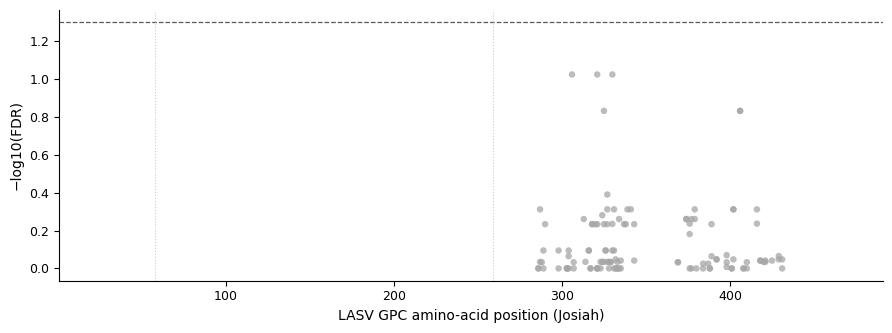

In [13]:
if len(residue_results):

    plot_df = residue_results.copy()
    plot_df['minus_log10_FDR'] = -np.log10(
        plot_df['FDR'].clip(lower=1e-300)
    )

    sig_res = plot_df.loc[
        plot_df['positive_enrichment']
    ].copy()

    fig, ax = plt.subplots(figsize=(9.0, 3.4))

    ax.scatter(
        plot_df['position'],
        plot_df['minus_log10_FDR'],
        s=22,
        color='0.65',
        alpha=0.75,
        edgecolor='none'
    )

    ax.scatter(
        sig_res['position'],
        sig_res['minus_log10_FDR'],
        s=34,
        color=SURVIVOR_COLOR,
        edgecolor='none',
        zorder=3
    )

    ax.axhline(
        -np.log10(0.05),
        color='0.35',
        lw=0.9,
        ls='--'
    )

    # GPC domain boundaries
    for x in [58, 259]:
        ax.axvline(
            x,
            color='0.80',
            lw=0.8,
            ls=':'
        )

    # Label strongest significant residues
    for _, r in sig_res.sort_values('FDR').head(12).iterrows():
        ax.annotate(
            r['label'],
            (r['position'], r['minus_log10_FDR']),
            xytext=(3, 4),
            textcoords='offset points',
            fontsize=7
        )

    ax.set_xlabel('LASV GPC amino-acid position (Josiah)')
    ax.set_ylabel('−log10(FDR)')

    if FOCUS_REGION is not None:
        ax.set_xlim(*FOCUS_REGION)
    else:
        ax.set_xlim(1, len(gpc_ref))

    fig.tight_layout()

    fig.savefig(
        OUTDIR / 'Mammarenavirus_GPC_residue_neutralization_Manhattan.svg',
        bbox_inches='tight'
    )
    fig.savefig(
        OUTDIR / 'Mammarenavirus_GPC_residue_neutralization_Manhattan.pdf',
        bbox_inches='tight'
    )

    plt.show()


## 8. Library coverage / informativeness track

This track is important for interpreting the Manhattan plot. Positions with little coverage or no natural sequence variation cannot provide strong residue-level inference.


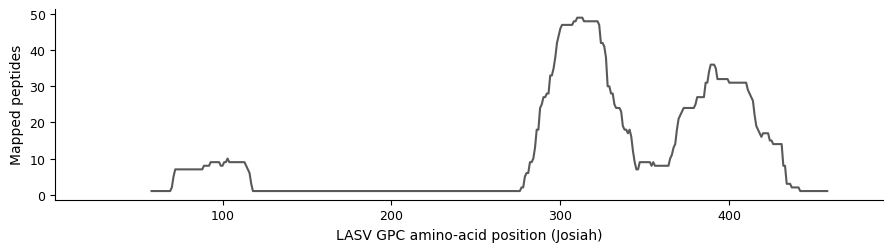

,position,n_peptides,n_unique_AA,n_hits,hit_fraction
132,324,42,13,36,0.857143
136,328,30,12,25,0.833333
140,332,25,12,23,0.920000
111,303,47,8,43,0.914894
141,333,24,8,22,0.916667
228,420,17,8,2,0.117647
129,321,48,7,42,0.875000
133,325,42,7,36,0.857143
112,304,47,6,43,0.914894
209,401,31,6,10,0.322581


In [14]:
coverage_rows = []

for pos, g in residue_long.groupby('position'):
    g = g.drop_duplicates('peptide')

    coverage_rows.append({
        'position': int(pos),
        'n_peptides': len(g),
        'n_unique_AA': g['aa'].nunique(),
        'n_hits': int(g['neutralization_hit'].sum()),
        'hit_fraction': g['neutralization_hit'].mean()
    })

coverage = pd.DataFrame(coverage_rows)

fig, ax = plt.subplots(figsize=(9.0, 2.6))

ax.plot(
    coverage['position'],
    coverage['n_peptides'],
    lw=1.5,
    color='0.35'
)

ax.set_xlabel('LASV GPC amino-acid position (Josiah)')
ax.set_ylabel('Mapped peptides')

if FOCUS_REGION is not None:
    ax.set_xlim(*FOCUS_REGION)
else:
    ax.set_xlim(1, len(gpc_ref))

fig.tight_layout()
plt.show()

display(
    coverage.sort_values(
        ['n_unique_AA','n_peptides'],
        ascending=False
    ).head(30)
)


## 9. Candidate residue table for structural comparison

Export only statistically supported positive residue identities, plus the strongest suggestive candidates. This table is the input for the next step: comparison with published LASV neutralizing-antibody contact, escape, and mutagenesis residues.

**Do not call these “critical residues” yet.** Preferred language:
- neutralization-associated residue identity
- candidate residue determinant
- residue nominated by natural sequence variation


In [15]:
if len(residue_results):

    candidate_residues = residue_results.loc[
        residue_results['positive_enrichment']
    ].sort_values('FDR').copy()

    suggestive_residues = residue_results.loc[
        (residue_results['delta_hit_fraction'] > 0)
        & (residue_results['FDR'] < 0.20)
    ].sort_values('FDR').copy()

    display(candidate_residues)
    print('\nSuggestive FDR < 0.20:')
    display(suggestive_residues.head(30))

    candidate_residues.to_csv(
        OUTDIR / 'Mammarenavirus_GPC_candidate_neutralization_residues.csv',
        index=False
    )

    residue_results.to_csv(
        OUTDIR / 'Mammarenavirus_GPC_all_residue_tests.csv',
        index=False
    )


,position,Josiah_AA,tested_AA,n_position,n_tested_AA,n_other_AA,hits_tested_AA,nonhits_tested_AA,hits_other_AA,nonhits_other_AA,hit_fraction_tested_AA,hit_fraction_other_AA,delta_hit_fraction,odds_ratio,p_value,FDR,positive_enrichment,label



Suggestive FDR < 0.20:


,position,Josiah_AA,tested_AA,n_position,n_tested_AA,n_other_AA,hits_tested_AA,nonhits_tested_AA,hits_other_AA,nonhits_other_AA,hit_fraction_tested_AA,hit_fraction_other_AA,delta_hit_fraction,odds_ratio,p_value,FDR,positive_enrichment,label
16,306,D,D,47,42,5,41,1,2,3,0.976190,0.4,0.576190,61.5,0.002383,0.094350,False,D306
101,406,Q,Q,31,6,25,5,1,5,20,0.833333,0.2,0.633333,20.0,0.007473,0.146963,False,Q406


## 10. Alignment-style display of positive peptide hits

This preserves the visualization that motivated the residue analysis. Dots indicate identity to Josiah; letters indicate substitutions. It is descriptive and complementary to the residue enrichment statistics above.


In [16]:
positive_mapped = mapped_screen.loc[
    mapped_screen['neutralization_hit']
].sort_values(['full_start','full_end']).reset_index(drop=True)

if len(positive_mapped):

    region_start = max(1, int(positive_mapped['full_start'].min()) - 3)
    region_end = min(len(gpc_ref), int(positive_mapped['full_end'].max()) + 3)

    josiah_region = gpc_ref[region_start-1:region_end]

    def make_aligned_display(seq, full_start, region_start, region_end):
        chars = [' '] * (region_end-region_start+1)
        for i, aa in enumerate(str(seq)):
            pos = int(full_start) + i
            if region_start <= pos <= region_end:
                chars[pos-region_start] = aa
        return ''.join(chars)

    def dot_matches(s, ref):
        out = []
        for aa, raa in zip(s, ref):
            if aa == ' ':
                out.append(' ')
            elif aa == raa:
                out.append('.')
            else:
                out.append(aa)
        return ''.join(out)

    print(f'Josiah {region_start}-{region_end}')
    print(josiah_region)

    for i, row in positive_mapped.iterrows():
        aligned = make_aligned_display(
            row['sequence'], row['full_start'],
            region_start, region_end
        )
        dotted = dot_matches(aligned, josiah_region)

        print(
            f'pep {i+1:>2}  {dotted}  '
            f'ΔNeut={row["delta_median_neut"]:+.1f}  '
            f'FDR={row["FDR_screen"]:.3g}'
        )


Josiah 69-439
QTLELNMETLNMTMPLSCTKNNSHHYIMVGNETGLELTLTNTSIINHKFCNLSDAHKKNLYDHALMSIISTFHLSIPNFNQYEAMSCDFNGGKISVQYNLSHSYAGDAANHCGTVANGVLQTFMRMAWGGSYIALDSGRGNWDCIMTSYQYLIIQNTTWEDHCQFSRPSPIGYLGLLSQRTRDIYISRRLLGTFTWTLSDSEGKDTPGGYCLTRWMLIEAELKCFGNTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALINDQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGKTPLGLVDLFVFSTS
pep  1     ..KGSQF.L...TL....DT....KIS.NS...V....S.LV.KN.                                                                                                                                                                                                                                                                                                                                    ΔNeut=+10.9  FDR=0.0491
pep  2                                                                                                                                                                                                         .P

## Interpretation checklist

A residue is most interesting when:

1. the aligned position has good peptide coverage;
2. there is genuine natural amino-acid variation at that position;
3. one amino-acid identity is enriched among neutralization-associated peptides;
4. the association survives FDR correction;
5. the result is not driven by only one viral sequence lineage;
6. the position overlaps or lies near a known neutralizing-antibody contact / escape / mutagenesis residue in LASV GPC structure.

The next analysis should therefore take `candidate_residues` and systematically compare them with published LASV GPC neutralizing-antibody structural footprints.
